# Milestone M4 — Exploratory Data Analysis (`notebooks/m4_eda.ipynb`)

**Project Question:** Which chess openings are associated with different game outcomes after accounting for the rating difference between the players and each player's color, and do these patterns change across rating groups?

### Engineering & Reproducibility Guarantees
1. **Strictly Read-Only Connection:** Opens `data/lichess.db` with `mode=ro` URI mode so no table can be modified.
2. **Parameterized SQL Only:** All filter thresholds are bound via `?` placeholders (zero string formatting in SQL).
3. **Top-to-Bottom Execution:** Runs cleanly via `Restart & Run All` on a fresh `load.py` + `clean.py` build and writes 7 figures to `figures/`.

In [17]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# --- M4 GLOBAL PARAMETERS (Single Source of Truth) ---
RANDOM_SEED = 42
LOCAL_TZ = "Europe/Istanbul"          # UTC+3; aligns timestamps with local human activity hours
MIN_GAMES_OPENING = 30                # Minimum sample size per opening for stable win-rate estimates
MIN_GAMES_SUBGROUP = 15               # Minimum sample size per opening x rating-band cell
RATING_BINS = [0, 1600, 1900, 4000]
RATING_LABELS = ["<1600 (Lower)", "1600-1899 (Mid)", "1900+ (Upper)"]
BIN_WIDTH_CHOICES = [25, 50, 100]     # Elo bin widths tested in Section 2.3
CHOSEN_ELO_BIN_WIDTH = 50             # Natural bullet Elo step selected after comparison
EXTREME_DIFF_CAP = 400                # Sensitivity threshold for |white_elo - black_elo|
N_BOOTSTRAP = 2000                    # Cluster bootstrap iterations for Section 2.7

# M3 Flag Filters (exact values from sql/clean_schema.sql)
FILTER_VARIANT = "Standard"
FILTER_TOURNAMENT_STATUS = 30
FILTER_STATUS_FLAG = "ok"
FILTER_OPENING_FLAG = "ok"
FILTER_MOVES_FLAG = "ok"
FILTER_ELO_FLAG = "ok"

# Resolve paths regardless of whether notebook runs from repo root or notebooks/
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

DB_PATH = REPO_ROOT / "data" / "lichess.db"
FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def connect_ro(db_path: Path = DB_PATH) -> sqlite3.Connection:
    """Open SQLite database strictly in read-only URI mode."""
    if not db_path.exists():
        raise FileNotFoundError(f"Database not found at {db_path}. Run load.py and clean.py first.")
    uri = f"file:{db_path.as_posix()}?mode=ro"
    return sqlite3.connect(uri, uri=True)


# Global matplotlib styling
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

# Quick read-only connection verification
with connect_ro() as conn:
    tables = pd.read_sql_query(
        "SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name;",
        conn,
    )
print(f"Connected read-only to: {DB_PATH}")
print(f"Figures output folder : {FIGURES_DIR}")
display(tables)

Connected read-only to: C:\Users\suden\OneDrive\Desktop\Lichessproje2\lichess-tournament-analysis\data\lichess.db
Figures output folder : C:\Users\suden\OneDrive\Desktop\Lichessproje2\lichess-tournament-analysis\figures


,name,type
0,category_map,table
1,game,table
2,game_clean,table
3,opening,table
4,opening_line,table
5,player,table
6,player_alias,table
7,quarantine_game,table
8,tournament,table
9,tournament_clean,table


## 2.1 Raw Versus Cleaned: The Key Number
**Question:** How much does the overall White win rate (`result = '1-0'`) change when moving from raw M2 tables (`game`) to the M3 cleaned layer (`game_resolved` + `tournament_named`) with our trusted flag filters (`Standard` variant, finished non-stale tournament, `opening_key_flag = 'ok'`, `moves_flag = 'ok'`)?

In [18]:
SQL_RAW_KEY = """
-- M2 Raw table: no variant or quality flag filter
SELECT
    'M2 Raw (all game rows)' AS layer,
    COUNT(*) AS n_games,
    SUM(CASE WHEN result = '1-0' THEN 1 ELSE 0 END) AS white_wins,
    SUM(CASE WHEN result = '0-1' THEN 1 ELSE 0 END) AS black_wins,
    SUM(CASE WHEN result = '1/2-1/2' THEN 1 ELSE 0 END) AS draws,
    ROUND(AVG(CASE WHEN result = '1-0' THEN 1.0 ELSE 0.0 END), 4) AS white_win_rate,
    ROUND(AVG(white_elo - black_elo), 2) AS mean_rating_diff
FROM game;
"""

SQL_CLEAN_KEY = """
-- M3 Cleaned layer: Standard variant, finished non-stale tournament, opening_key_flag='ok', moves_flag='ok'
SELECT
    'M3 Cleaned (Standard, opening+moves ok)' AS layer,
    COUNT(*) AS n_games,
    SUM(CASE WHEN g.result = '1-0' THEN 1 ELSE 0 END) AS white_wins,
    SUM(CASE WHEN g.result = '0-1' THEN 1 ELSE 0 END) AS black_wins,
    SUM(CASE WHEN g.result = '1/2-1/2' THEN 1 ELSE 0 END) AS draws,
    ROUND(AVG(CASE WHEN g.result = '1-0' THEN 1.0 ELSE 0.0 END), 4) AS white_win_rate,
    ROUND(AVG(g.white_elo - g.black_elo), 2) AS mean_rating_diff
FROM game_resolved g
JOIN tournament_named t ON t.tournament_key = g.tournament_key
WHERE t.variant = ?
  AND t.status = ?
  AND t.status_flag = ?
  AND g.opening_key_flag = ?
  AND g.moves_flag = ?;
"""

with connect_ro() as conn:
    df_raw_key = pd.read_sql_query(SQL_RAW_KEY, conn)
    df_clean_key = pd.read_sql_query(
        SQL_CLEAN_KEY,
        conn,
        params=(
            FILTER_VARIANT,
            FILTER_TOURNAMENT_STATUS,
            FILTER_STATUS_FLAG,
            FILTER_OPENING_FLAG,
            FILTER_MOVES_FLAG,
        ),
    )

df_2_1 = pd.concat([df_raw_key, df_clean_key], ignore_index=True)
diff_pp = (df_2_1.loc[1, "white_win_rate"] - df_2_1.loc[0, "white_win_rate"]) * 100
dropped_n = df_2_1.loc[0, "n_games"] - df_2_1.loc[1, "n_games"]

print("--- SQL Query 1 (M2 Raw) ---")
print(SQL_RAW_KEY.strip())
print("\n--- SQL Query 2 (M3 Cleaned) ---")
print(SQL_CLEAN_KEY.strip())
display(df_2_1)
print(f"Excluded rows: {dropped_n} games (338 Atomic/Chess960, 49 Standard missing opening, plus remaining Standard no_moves_played).")
print(f"White win rate shift (Cleaned - Raw): {diff_pp:+.2f} percentage points.")

--- SQL Query 1 (M2 Raw) ---
-- M2 Raw table: no variant or quality flag filter
SELECT
    'M2 Raw (all game rows)' AS layer,
    COUNT(*) AS n_games,
    SUM(CASE WHEN result = '1-0' THEN 1 ELSE 0 END) AS white_wins,
    SUM(CASE WHEN result = '0-1' THEN 1 ELSE 0 END) AS black_wins,
    SUM(CASE WHEN result = '1/2-1/2' THEN 1 ELSE 0 END) AS draws,
    ROUND(AVG(CASE WHEN result = '1-0' THEN 1.0 ELSE 0.0 END), 4) AS white_win_rate,
    ROUND(AVG(white_elo - black_elo), 2) AS mean_rating_diff
FROM game;

--- SQL Query 2 (M3 Cleaned) ---
-- M3 Cleaned layer: Standard variant, finished non-stale tournament, opening_key_flag='ok', moves_flag='ok'
SELECT
    'M3 Cleaned (Standard, opening+moves ok)' AS layer,
    COUNT(*) AS n_games,
    SUM(CASE WHEN g.result = '1-0' THEN 1 ELSE 0 END) AS white_wins,
    SUM(CASE WHEN g.result = '0-1' THEN 1 ELSE 0 END) AS black_wins,
    SUM(CASE WHEN g.result = '1/2-1/2' THEN 1 ELSE 0 END) AS draws,
    ROUND(AVG(CASE WHEN g.result = '1-0' THEN 1.0 ELSE 

,layer,n_games,white_wins,black_wins,draws,white_win_rate,mean_rating_diff
0,M2 Raw (all game rows),4535,2302,2128,105,0.5076,1.46
1,"M3 Cleaned (Standard, opening+moves ok)",4148,2113,1938,97,0.5094,2.90


Excluded rows: 387 games (338 Atomic/Chess960, 49 Standard missing opening, plus remaining Standard no_moves_played).
White win rate shift (Cleaned - Raw): +0.18 percentage points.


## 2.2 The Project Question and Chosen Summary Metric
**Project Question:** After accounting for player rating difference and piece color, which chess openings are associated with distinct game outcomes in bullet arena tournaments, and do these opening patterns vary across rating bands?

- **Primary summary:** **White win rate** (`P(result = '1-0')`), reported with exact sample size `n`. Because bullet games are decisive ~96% of the time, win rate directly measures White's realized advantage per opening.
- **Alternative summary:** **White expected score** (`1.0` win, `0.5` draw, `0.0` loss) and **mean rating difference (`white_elo - black_elo`)**, checking whether draw rates or pairing rating imbalances alter the opening ranking.

Openings meeting n >= 30: 25


,eco,name,n_games,white_win_rate,white_expected_score,draw_rate,mean_rating_diff,rank_win_rate,rank_exp_score,rank_shift
0,A40,Queen's Pawn Game: Modern Defense,56,0.6607,0.6786,0.0357,117.7,1,1,0
1,A40,Englund Gambit,52,0.6538,0.6731,0.0385,123.4,2,2,0
2,C41,Philidor Defense,37,0.6486,0.6486,0.0000,43.5,3,3,0
3,A00,Saragossa Opening,48,0.6042,0.6146,0.0208,57.1,4,5,-1
4,A01,Nimzo-Larsen Attack,45,0.6000,0.6222,0.0444,5.4,5,4,1
5,A40,English Defense,32,0.5938,0.5938,0.0000,112.3,6,6,0
6,A40,Horwitz Defense,71,0.5775,0.5845,0.0141,57.7,7,7,0
7,A00,Hungarian Opening,54,0.5741,0.5741,0.0000,43.5,8,8,0
8,B01,Scandinavian Defense: Mieses-Kotroc Variation,44,0.5682,0.5682,0.0000,39.7,9,9,0
9,A00,Mieses Opening,47,0.5319,0.5532,0.0426,81.4,10,10,0


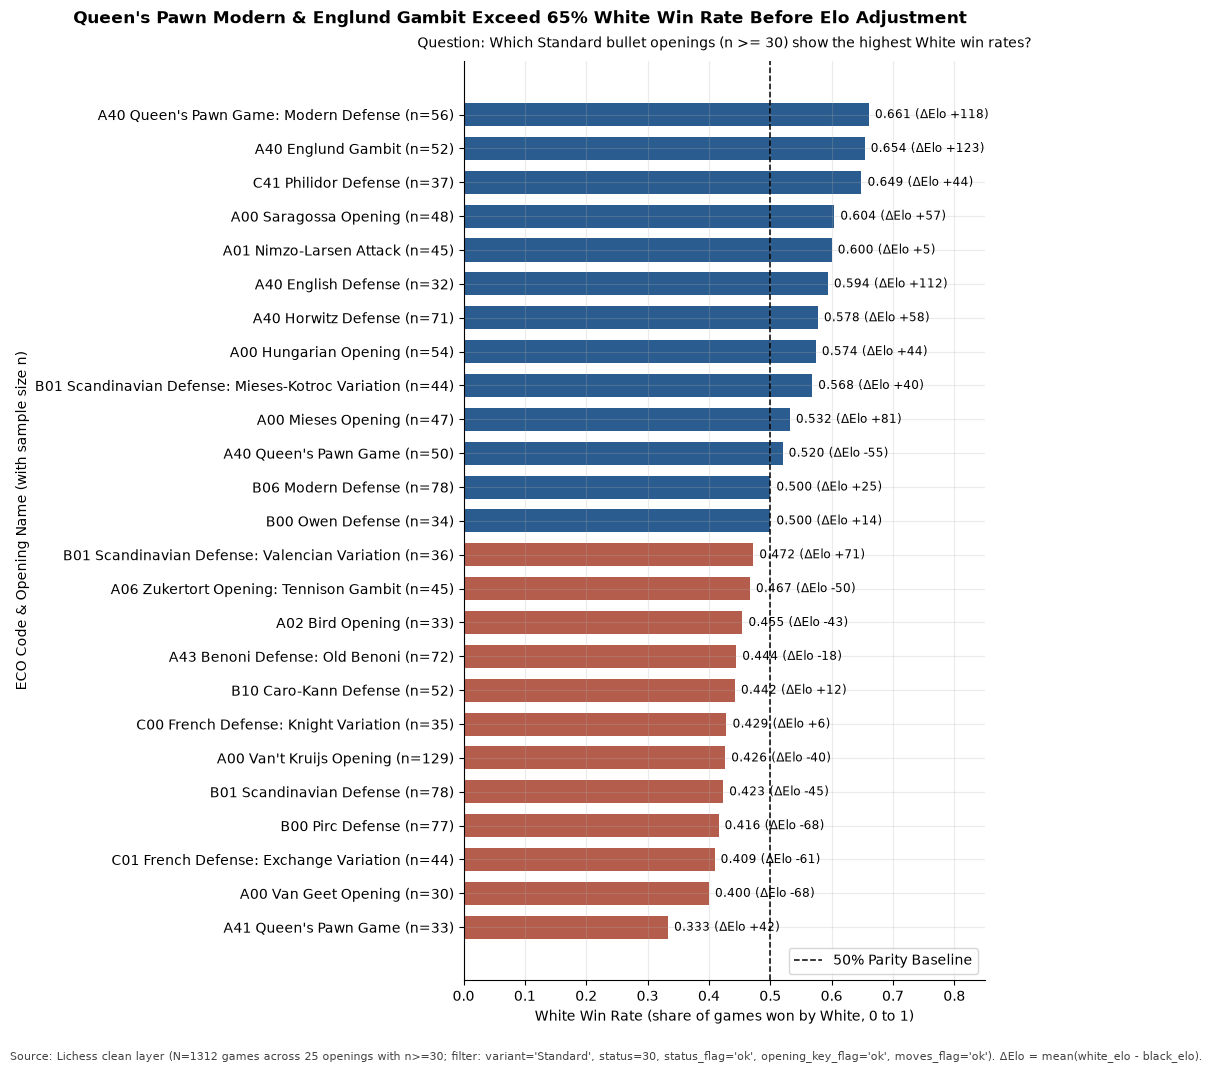

In [19]:
SQL_OPENING_SUMMARY = """
-- Filter: variant='Standard', status=30, status_flag='ok', opening_key_flag='ok', moves_flag='ok'
SELECT
    o.eco,
    o.name,
    COUNT(*) AS n_games,
    ROUND(AVG(CASE WHEN g.result = '1-0' THEN 1.0 ELSE 0.0 END), 4) AS white_win_rate,
    ROUND(AVG(CASE WHEN g.result = '1-0' THEN 1.0 WHEN g.result = '1/2-1/2' THEN 0.5 ELSE 0.0 END), 4) AS white_expected_score,
    ROUND(AVG(CASE WHEN g.result = '1/2-1/2' THEN 1.0 ELSE 0.0 END), 4) AS draw_rate,
    ROUND(AVG(g.white_elo - g.black_elo), 1) AS mean_rating_diff
FROM game_resolved g
JOIN tournament_named t ON t.tournament_key = g.tournament_key
JOIN opening o ON o.opening_key = g.opening_key
WHERE t.variant = ?
  AND t.status = ?
  AND t.status_flag = ?
  AND g.opening_key_flag = ?
  AND g.moves_flag = ?
GROUP BY o.opening_key, o.eco, o.name
HAVING COUNT(*) >= ?
ORDER BY white_win_rate DESC, n_games DESC;
"""

with connect_ro() as conn:
    df_openings_30 = pd.read_sql_query(
        SQL_OPENING_SUMMARY,
        conn,
        params=(
            FILTER_VARIANT,
            FILTER_TOURNAMENT_STATUS,
            FILTER_STATUS_FLAG,
            FILTER_OPENING_FLAG,
            FILTER_MOVES_FLAG,
            MIN_GAMES_OPENING,
        ),
    )

df_openings_30["rank_win_rate"] = df_openings_30["white_win_rate"].rank(ascending=False, method="min").astype(int)
df_openings_30["rank_exp_score"] = df_openings_30["white_expected_score"].rank(ascending=False, method="min").astype(int)
df_openings_30["rank_shift"] = df_openings_30["rank_win_rate"] - df_openings_30["rank_exp_score"]

print(f"Openings meeting n >= {MIN_GAMES_OPENING}: {len(df_openings_30)}")
display(df_openings_30)

# --- FIGURE 1 (Headline Figure for README) ---
plot_df = df_openings_30.sort_values("white_win_rate", ascending=True).copy()
labels = [f"{r.eco} {r.name} (n={r.n_games})" for r in plot_df.itertuples()]

fig, ax = plt.subplots(figsize=(10, max(5, 0.42 * len(plot_df))))
colors = ["#2b5c8f" if wr >= 0.50 else "#b55d4c" for wr in plot_df["white_win_rate"]]
bars = ax.barh(labels, plot_df["white_win_rate"], color=colors, edgecolor="none", height=0.68)

ax.axvline(0.50, color="black", linestyle="--", linewidth=1.1, label="50% Parity Baseline")
ax.set_xlim(0, 0.85)  # Bars start at 0 per checklist
ax.set_xlabel("White Win Rate (share of games won by White, 0 to 1)")
ax.set_ylabel("ECO Code & Opening Name (with sample size n)")

for bar, row in zip(bars, plot_df.itertuples()):
    ax.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{row.white_win_rate:.3f} (ΔElo {row.mean_rating_diff:+.0f})",
        va="center",
        fontsize=8.5,
    )

fig.suptitle(
    "Queen's Pawn Modern & Englund Gambit Exceed 65% White Win Rate Before Elo Adjustment",
    fontsize=12.5,
    fontweight="bold",
    x=0.52,
)
ax.set_title(
    f"Question: Which Standard bullet openings (n >= {MIN_GAMES_OPENING}) show the highest White win rates?",
    fontsize=10,
    pad=10,
)
ax.legend(loc="lower right", frameon=True)
fig.text(
    0.01,
    -0.02,
    f"Source: Lichess clean layer (N={df_openings_30['n_games'].sum()} games across {len(df_openings_30)} openings with n>={MIN_GAMES_OPENING}; "
    f"filter: variant='Standard', status=30, status_flag='ok', opening_key_flag='ok', moves_flag='ok'). ΔElo = mean(white_elo - black_elo).",
    fontsize=8,
    color="#444444",
)
fig.tight_layout()
fig1_path = FIGURES_DIR / "fig1_headline_opening_winrates.png"
fig.savefig(fig1_path, dpi=150, bbox_inches="tight")
plt.show()

## 2.3 Distribution Shape of Rating Difference and Opening Sample Sizes
**Question:** What is the distributional shape of `rating_diff` (`white_elo - black_elo`) across the dataset and across rating bands, and how skewed are opening sample sizes?

Bin width  25 Elo -> 40 bins, max bin count = 199
Bin width  50 Elo -> 20 bins, max bin count = 378
Bin width 100 Elo -> 10 bins, max bin count = 657

Rating difference summary by rating band:


,n,mean,std,median,iqr
rating_band,,,,,
<1600 (Lower),741,-2.49,384.77,-6.0,388.00
1600-1899 (Mid),1600,10.11,324.98,3.0,412.75
1900+ (Upper),1807,-1.28,295.62,-2.0,320.50


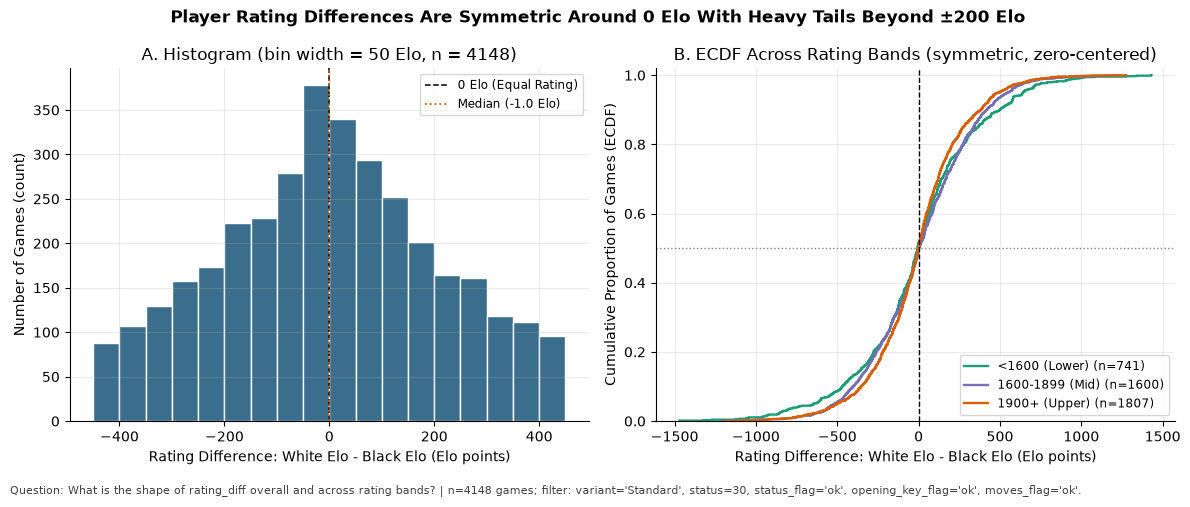

In [20]:
SQL_CLEAN_GAMES = """
-- Filter: variant='Standard', status=30, status_flag='ok', opening_key_flag='ok', moves_flag='ok'
SELECT
    g.game_id,
    g.tournament_key,
    t.full_name AS tournament_name,
    g.white_resolved_key,
    g.black_resolved_key,
    g.opening_key,
    o.eco,
    o.name AS opening_name,
    g.played_at,
    g.result,
    g.termination,
    g.white_elo,
    g.black_elo,
    (g.white_elo - g.black_elo) AS rating_diff,
    ((g.white_elo + g.black_elo) / 2.0) AS mean_pair_elo,
    g.white_elo_flag,
    g.black_elo_flag,
    g.moves_flag
FROM game_resolved g
JOIN tournament_named t ON t.tournament_key = g.tournament_key
JOIN opening o ON o.opening_key = g.opening_key
WHERE t.variant = ?
  AND t.status = ?
  AND t.status_flag = ?
  AND g.opening_key_flag = ?
  AND g.moves_flag = ?;
"""

with connect_ro() as conn:
    df_games = pd.read_sql_query(
        SQL_CLEAN_GAMES,
        conn,
        params=(
            FILTER_VARIANT,
            FILTER_TOURNAMENT_STATUS,
            FILTER_STATUS_FLAG,
            FILTER_OPENING_FLAG,
            FILTER_MOVES_FLAG,
        ),
    )

df_games["white_win"] = (df_games["result"] == "1-0").astype(int)
df_games["rating_band"] = pd.cut(
    df_games["mean_pair_elo"],
    bins=RATING_BINS,
    labels=RATING_LABELS,
    right=False,
)

# Compare 3 bin widths for rating_diff (25, 50, 100 Elo)
for bw in BIN_WIDTH_CHOICES:
    bins = np.arange(-500, 500 + bw, bw)
    counts, _ = np.histogram(df_games["rating_diff"], bins=bins)
    print(f"Bin width {bw:3d} Elo -> {len(bins)-1:2d} bins, max bin count = {counts.max()}")

print("\nRating difference summary by rating band:")
display(
    df_games.groupby("rating_band", observed=False)["rating_diff"].agg(
        n="count", mean="mean", std="std", median="median", iqr=lambda s: s.quantile(0.75) - s.quantile(0.25)
    ).round(2)
)

# --- FIGURE 2: Two complementary views of shape (Histogram + ECDF by rating band) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Panel A: Histogram with chosen 50-Elo bin width
bins_50 = np.arange(-450, 450 + CHOSEN_ELO_BIN_WIDTH, CHOSEN_ELO_BIN_WIDTH)
axes[0].hist(df_games["rating_diff"], bins=bins_50, color="#3b6e8c", edgecolor="white")
axes[0].axvline(0, color="black", linestyle="--", linewidth=1.1, label="0 Elo (Equal Rating)")
axes[0].axvline(df_games["rating_diff"].median(), color="#d95f02", linestyle=":", linewidth=1.3,
                label=f"Median ({df_games['rating_diff'].median():.1f} Elo)")
axes[0].set_ylim(bottom=0)
axes[0].set_xlabel("Rating Difference: White Elo - Black Elo (Elo points)")
axes[0].set_ylabel("Number of Games (count)")
axes[0].set_title(f"A. Histogram (bin width = {CHOSEN_ELO_BIN_WIDTH} Elo, n = {len(df_games)})")
axes[0].legend(frameon=True, fontsize=8.5)

# Panel B: ECDF overall and by rating band
band_colors = {"<1600 (Lower)": "#1b9e77", "1600-1899 (Mid)": "#7570b3", "1900+ (Upper)": "#d95f02"}
for band in RATING_LABELS:
    sub = np.sort(df_games.loc[df_games["rating_band"] == band, "rating_diff"].to_numpy())
    ecdf_y = np.arange(1, len(sub) + 1) / len(sub)
    axes[1].step(sub, ecdf_y, where="post", linewidth=1.7, color=band_colors[band],
                 label=f"{band} (n={len(sub)})")

axes[1].axvline(0, color="black", linestyle="--", linewidth=1.0)
axes[1].axhline(0.50, color="gray", linestyle=":", linewidth=1.0)
axes[1].set_ylim(0, 1.02)
axes[1].set_xlabel("Rating Difference: White Elo - Black Elo (Elo points)")
axes[1].set_ylabel("Cumulative Proportion of Games (ECDF)")
axes[1].set_title("B. ECDF Across Rating Bands (symmetric, zero-centered)")
axes[1].legend(loc="lower right", frameon=True, fontsize=8.5)

fig.suptitle(
    "Player Rating Differences Are Symmetric Around 0 Elo With Heavy Tails Beyond ±200 Elo",
    fontsize=12.5,
    fontweight="bold",
)
fig.text(
    0.01,
    -0.03,
    f"Question: What is the shape of rating_diff overall and across rating bands? | n={len(df_games)} games; "
    "filter: variant='Standard', status=30, status_flag='ok', opening_key_flag='ok', moves_flag='ok'.",
    fontsize=8,
    color="#444444",
)
fig.tight_layout()
fig2_path = FIGURES_DIR / "fig2_rating_diff_shape.png"
fig.savefig(fig2_path, dpi=150, bbox_inches="tight")
plt.show()

## 2.4 Coverage, Denominators, and Flag Filter Sensitivity
**Question:** How much of the raw tournament and game data survives into our analysis denominator, how does enforcing the `n >= 30` coverage rule change extreme win rates, and how sensitive are results to strict vs. permissive flag filters?

1. Coverage & Flag Breakdown Table:


,variant,status_flag,opening_key_flag,moves_flag,elo_pair_flag,n_games,white_win_rate
0,Standard,ok,ok,ok,ok,3959,0.5095
1,Atomic,ok,missing_variant_has_no_openings,ok,ok,237,0.5865
2,Standard,ok,ok,ok,elo_flagged,189,0.5079
3,Chess960,ok,missing_variant_has_no_openings,ok,ok,101,0.4950
4,Standard,ok,missing_not_reported,ok,ok,42,0.0000
5,Standard,ok,missing_not_reported,ok,elo_flagged,7,0.0000



2. Top 5 openings WITHOUT coverage rule (n >= 1, total openings = 611):


,eco,name,n_games,white_win_rate
0,A00,Hungarian Opening: Sicilian Invitation,6,1.0
1,D08,Queen's Gambit Declined: Albin Countergambit,5,1.0
2,D38,Queen's Gambit Declined: Ragozin Defense,5,1.0
3,A04,Zukertort Opening,4,1.0
4,B12,"Caro-Kann Defense: Advance Variation, Botvinni...",4,1.0


3. Top 5 openings WITH coverage rule (n >= 30, retained openings = 25):


,eco,name,n_games,white_win_rate
0,A40,Queen's Pawn Game: Modern Defense,56,0.6607
1,A40,Englund Gambit,52,0.6538
2,C41,Philidor Defense,37,0.6486
3,A00,Saragossa Opening,48,0.6042
4,A01,Nimzo-Larsen Attack,45,0.6000



4. Flag Filter Comparison (Baseline Clean vs Strict Elo='ok'):


,eco,name,n_games,white_win_rate,n_games_strict,white_win_rate_strict,win_rate_diff_pp
0,A40,Queen's Pawn Game: Modern Defense,56,0.6607,53,0.6604,-0.03
1,A40,Englund Gambit,52,0.6538,49,0.6327,-2.11
2,C41,Philidor Defense,37,0.6486,34,0.6176,-3.10
3,A00,Saragossa Opening,48,0.6042,47,0.5957,-0.85
4,A01,Nimzo-Larsen Attack,45,0.6000,45,0.6000,0.00
5,A40,English Defense,32,0.5938,31,0.5806,-1.32
6,A40,Horwitz Defense,71,0.5775,71,0.5775,0.00
7,A00,Hungarian Opening,54,0.5741,50,0.5800,0.59
8,B01,Scandinavian Defense: Mieses-Kotroc Variation,44,0.5682,40,0.6000,3.18
9,A00,Mieses Opening,47,0.5319,44,0.5227,-0.92


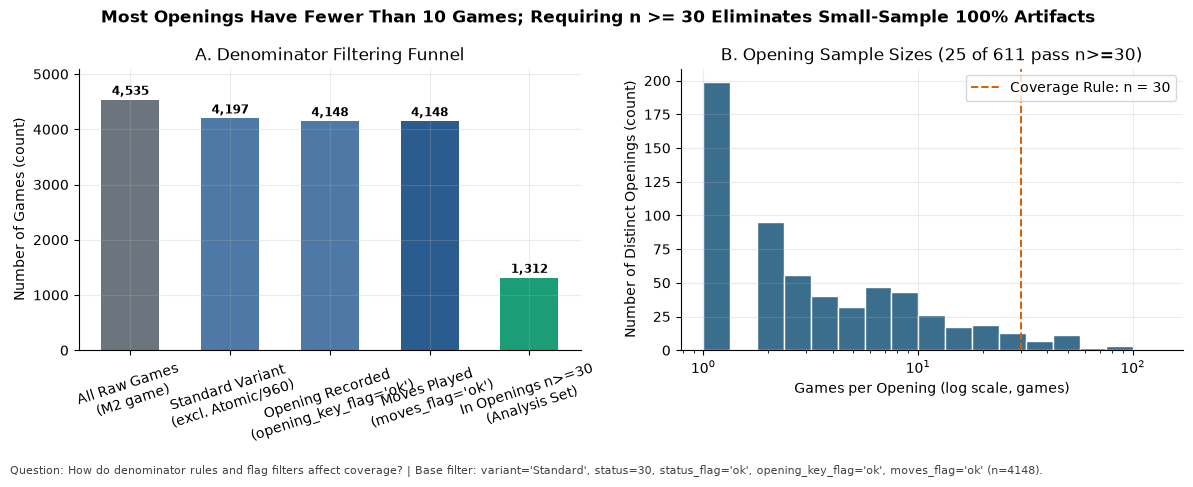

In [21]:
SQL_COVERAGE_BREAKDOWN = """
-- Full game_resolved + tournament_named breakdown across variants and M3 flags
SELECT
    t.variant,
    t.status_flag,
    g.opening_key_flag,
    g.moves_flag,
    CASE WHEN g.white_elo_flag = 'ok' AND g.black_elo_flag = 'ok' THEN 'ok' ELSE 'elo_flagged' END AS elo_pair_flag,
    COUNT(*) AS n_games,
    ROUND(AVG(CASE WHEN g.result = '1-0' THEN 1.0 ELSE 0.0 END), 4) AS white_win_rate
FROM game_resolved g
JOIN tournament_named t ON t.tournament_key = g.tournament_key
GROUP BY t.variant, t.status_flag, g.opening_key_flag, g.moves_flag, elo_pair_flag
ORDER BY n_games DESC;
"""

SQL_ALL_OPENINGS_NO_RULE = """
-- All Standard openings (n >= 1) to compare WITH vs WITHOUT the n >= 30 coverage rule
SELECT
    o.eco,
    o.name,
    COUNT(*) AS n_games,
    ROUND(AVG(CASE WHEN g.result = '1-0' THEN 1.0 ELSE 0.0 END), 4) AS white_win_rate
FROM game_resolved g
JOIN tournament_named t ON t.tournament_key = g.tournament_key
JOIN opening o ON o.opening_key = g.opening_key
WHERE t.variant = ?
  AND t.status = ?
  AND t.status_flag = ?
  AND g.opening_key_flag = ?
  AND g.moves_flag = ?
GROUP BY o.opening_key, o.eco, o.name
ORDER BY white_win_rate DESC, n_games DESC;
"""

SQL_STRICT_ELO_FILTER = """
-- Strict filter: also requires white_elo_flag = 'ok' AND black_elo_flag = 'ok'
SELECT
    o.eco,
    o.name,
    COUNT(*) AS n_games_strict,
    ROUND(AVG(CASE WHEN g.result = '1-0' THEN 1.0 ELSE 0.0 END), 4) AS white_win_rate_strict
FROM game_resolved g
JOIN tournament_named t ON t.tournament_key = g.tournament_key
JOIN opening o ON o.opening_key = g.opening_key
WHERE t.variant = ?
  AND t.status = ?
  AND t.status_flag = ?
  AND g.opening_key_flag = ?
  AND g.moves_flag = ?
  AND g.white_elo_flag = ?
  AND g.black_elo_flag = ?
GROUP BY o.opening_key, o.eco, o.name
HAVING COUNT(*) >= ?;
"""

with connect_ro() as conn:
    df_cov = pd.read_sql_query(SQL_COVERAGE_BREAKDOWN, conn)
    df_all_openings = pd.read_sql_query(
        SQL_ALL_OPENINGS_NO_RULE,
        conn,
        params=(
            FILTER_VARIANT,
            FILTER_TOURNAMENT_STATUS,
            FILTER_STATUS_FLAG,
            FILTER_OPENING_FLAG,
            FILTER_MOVES_FLAG,
        ),
    )
    df_strict_openings = pd.read_sql_query(
        SQL_STRICT_ELO_FILTER,
        conn,
        params=(
            FILTER_VARIANT,
            FILTER_TOURNAMENT_STATUS,
            FILTER_STATUS_FLAG,
            FILTER_OPENING_FLAG,
            FILTER_MOVES_FLAG,
            FILTER_ELO_FLAG,
            FILTER_ELO_FLAG,
            MIN_GAMES_OPENING,
        ),
    )

print("1. Coverage & Flag Breakdown Table:")
display(df_cov)

print(f"\n2. Top 5 openings WITHOUT coverage rule (n >= 1, total openings = {len(df_all_openings)}):")
display(df_all_openings.head(5))

print(f"3. Top 5 openings WITH coverage rule (n >= {MIN_GAMES_OPENING}, retained openings = {len(df_openings_30)}):")
display(df_openings_30[["eco", "name", "n_games", "white_win_rate"]].head(5))

# Compare Filter A (base clean) vs Filter B (strict Elo 'ok' only)
df_filter_cmp = pd.merge(
    df_openings_30[["eco", "name", "n_games", "white_win_rate"]],
    df_strict_openings,
    on=["eco", "name"],
    how="left",
)
df_filter_cmp["win_rate_diff_pp"] = (
    (df_filter_cmp["white_win_rate_strict"] - df_filter_cmp["white_win_rate"]) * 100
).round(2)
print("\n4. Flag Filter Comparison (Baseline Clean vs Strict Elo='ok'):")
display(df_filter_cmp)

# --- FIGURE 3: Coverage Funnel & Skewed Opening Sample Sizes (Log Scale) ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

stages = [
    "All Raw Games\n(M2 game)",
    "Standard Variant\n(excl. Atomic/960)",
    "Opening Recorded\n(opening_key_flag='ok')",
    "Moves Played\n(moves_flag='ok')",
    "In Openings n>=30\n(Analysis Set)",
]
stage_counts = [
    4535,
    int(df_cov.loc[df_cov["variant"] == "Standard", "n_games"].sum()),
    int(df_cov.loc[(df_cov["variant"] == "Standard") & (df_cov["opening_key_flag"] == "ok"), "n_games"].sum()),
    len(df_games),
    int(df_openings_30["n_games"].sum()),
]

bars = axes[0].bar(stages, stage_counts, color=["#6c757d", "#4e79a7", "#4e79a7", "#2b5c8f", "#1b9e77"], width=0.58)
axes[0].set_ylim(0, 5100)
axes[0].set_ylabel("Number of Games (count)")
axes[0].set_title("A. Denominator Filtering Funnel")
axes[0].tick_params(axis="x", rotation=18)
for b, val in zip(bars, stage_counts):
    axes[0].text(b.get_x() + b.get_width() / 2, val + 90, f"{val:,}", ha="center", fontsize=8.5, fontweight="bold")

# Panel B: Log-scale histogram of games per opening (shape of right-skewed count)
log_bins = np.logspace(0, np.log10(df_all_openings["n_games"].max() + 5), 18)
axes[1].hist(df_all_openings["n_games"], bins=log_bins, color="#3b6e8c", edgecolor="white")
axes[1].set_xscale("log")
axes[1].axvline(MIN_GAMES_OPENING, color="#d95f02", linestyle="--", linewidth=1.4,
                label=f"Coverage Rule: n = {MIN_GAMES_OPENING}")
axes[1].set_ylim(bottom=0)
axes[1].set_xlabel("Games per Opening (log scale, games)")
axes[1].set_ylabel("Number of Distinct Openings (count)")
axes[1].set_title(f"B. Opening Sample Sizes ({len(df_openings_30)} of {len(df_all_openings)} pass n>={MIN_GAMES_OPENING})")
axes[1].legend(frameon=True)

fig.suptitle(
    "Most Openings Have Fewer Than 10 Games; Requiring n >= 30 Eliminates Small-Sample 100% Artifacts",
    fontsize=12,
    fontweight="bold",
)
fig.text(
    0.01,
    -0.03,
    f"Question: How do denominator rules and flag filters affect coverage? | Base filter: variant='Standard', status=30, "
    f"status_flag='ok', opening_key_flag='ok', moves_flag='ok' (n={len(df_games)}).",
    fontsize=8,
    color="#444444",
)
fig.tight_layout()
fig3_path = FIGURES_DIR / "fig3_coverage_and_filters.png"
fig.savefig(fig3_path, dpi=150, bbox_inches="tight")
plt.show()

## 2.5 Time Dimension: Local Clock Conversion, Edge Completeness, and Two Time Scales
**Question:** How are bullet games distributed across local hours (`Europe/Istanbul`, UTC+3) and across tournaments/days, and are the first and last capture edges complete?

Time span in UTC  : 2026-10-08 11:30:12+00:00 -> 2026-10-09 17:55:47+00:00
Time span in Europe/Istanbul: 2026-10-08 14:30:12+03:00 -> 2026-10-09 20:55:47+03:00

Scale 1 — Local Calendar Day & Edge Window Check:


,local_date,local_dow,n_games,first_game_local,last_game_local,white_win_rate
0,2026-10-08,Thursday,1716,2026-10-08 14:30:12+03:00,2026-10-08 14:57:01+03:00,0.5280
1,2026-10-09,Friday,2432,2026-10-09 20:00:15+03:00,2026-10-09 20:55:47+03:00,0.4963



Scale 2 — Hourly Distribution (Europe/Istanbul, UTC+3):


,n_games,white_win_rate
local_hour,,
14,1716.0,0.5280
20,2432.0,0.4963



Tournament-level timeline:


,tournament_key,tournament_name,n_games,start_local,end_local,white_win_rate
2,121,≤2000 Bullet Arena,183,2026-10-08 14:30:12+03:00,2026-10-08 14:55:37+03:00,0.5191
1,119,Hourly Bullet Arena,936,2026-10-08 14:30:21+03:00,2026-10-08 14:56:48+03:00,0.5246
0,117,Hourly UltraBullet Arena,597,2026-10-08 14:30:43+03:00,2026-10-08 14:57:01+03:00,0.5360
4,273,Hourly Bullet Arena,1113,2026-10-09 20:00:15+03:00,2026-10-09 20:26:23+03:00,0.4852
3,260,Hourly Bullet Arena,1319,2026-10-09 20:30:22+03:00,2026-10-09 20:55:47+03:00,0.5057


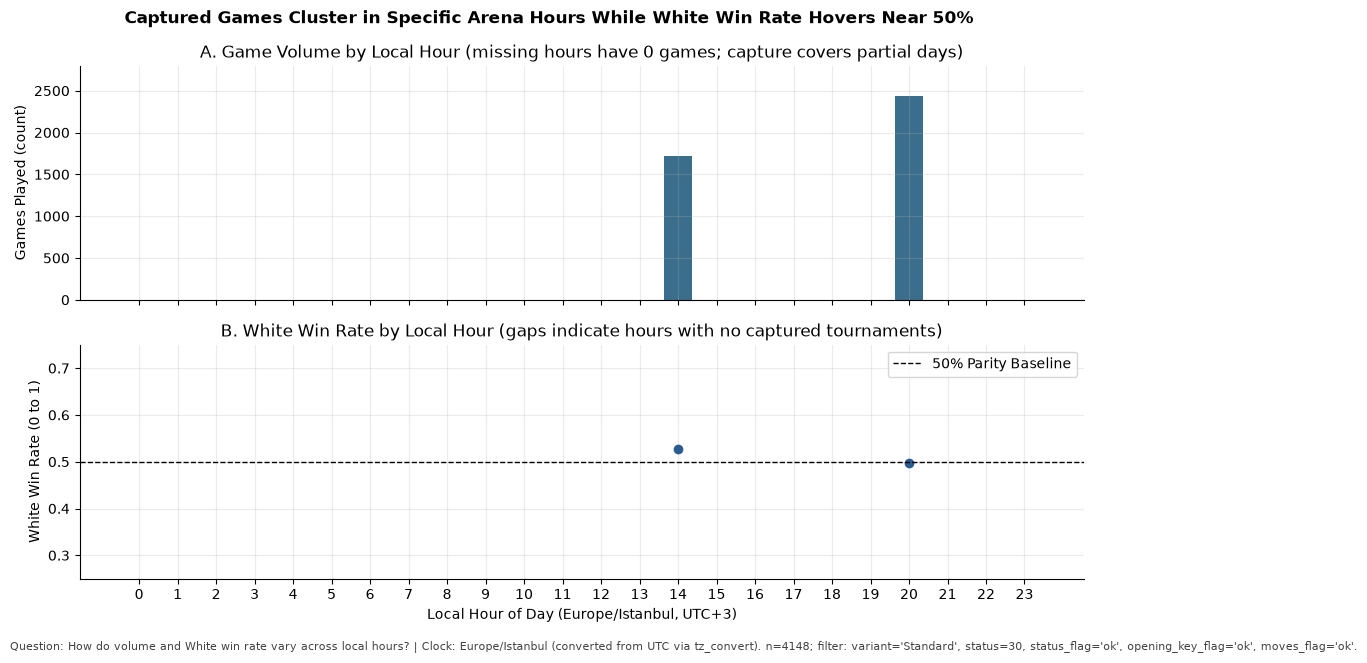

In [22]:
# Explicit timezone conversion (never group human behavior by raw UTC hour)
ts_utc = pd.to_datetime(df_games["played_at"], utc=True)
ts_local = ts_utc.dt.tz_convert(LOCAL_TZ)

df_games["played_at_local"] = ts_local
df_games["local_date"] = ts_local.dt.date
df_games["local_hour"] = ts_local.dt.hour
df_games["local_dow"] = ts_local.dt.day_name()

print("Time span in UTC  :", ts_utc.min(), "->", ts_utc.max())
print(f"Time span in {LOCAL_TZ}:", ts_local.min(), "->", ts_local.max())

# Scale 1: Local Date & Day of Week (Edge completeness check)
df_daily = (
    df_games.groupby(["local_date", "local_dow"], as_index=False)
    .agg(
        n_games=("game_id", "count"),
        first_game_local=("played_at_local", "min"),
        last_game_local=("played_at_local", "max"),
        white_win_rate=("white_win", "mean"),
    )
)
df_daily["white_win_rate"] = df_daily["white_win_rate"].round(4)
print("\nScale 1 — Local Calendar Day & Edge Window Check:")
display(df_daily)

# Scale 2: Local Hour of Day (reindex 0..23 so missing hours remain NaN gaps)
df_hourly = (
    df_games.groupby("local_hour")
    .agg(n_games=("game_id", "count"), white_win_rate=("white_win", "mean"))
    .reindex(range(24))
)
df_hourly.index.name = "local_hour"
print("\nScale 2 — Hourly Distribution (Europe/Istanbul, UTC+3):")
display(df_hourly.dropna().round(4))

# Tournament-level breakdown across the Standard tournaments with games
df_tourn_time = (
    df_games.groupby(["tournament_key", "tournament_name"], as_index=False)
    .agg(
        n_games=("game_id", "count"),
        start_local=("played_at_local", "min"),
        end_local=("played_at_local", "max"),
        white_win_rate=("white_win", "mean"),
    )
    .sort_values("start_local")
)
df_tourn_time["white_win_rate"] = df_tourn_time["white_win_rate"].round(4)
print("\nTournament-level timeline:")
display(df_tourn_time)

# --- FIGURE 4: Two stacked panels (No dual y-axes; missing hours left as gaps) ---
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)

hours = np.arange(24)
axes[0].bar(hours, df_hourly["n_games"].fillna(0), color="#3b6e8c", width=0.72)
axes[0].set_ylim(0, df_hourly["n_games"].max() * 1.15)
axes[0].set_ylabel("Games Played (count)")
axes[0].set_title("A. Game Volume by Local Hour (missing hours have 0 games; capture covers partial days)")

# Line plot with NaN gaps preserved (never connect across missing hours)
axes[1].plot(hours, df_hourly["white_win_rate"], marker="o", linewidth=1.8, color="#2b5c8f")
axes[1].axhline(0.50, color="black", linestyle="--", linewidth=1.0, label="50% Parity Baseline")
axes[1].set_ylim(0.25, 0.75)
axes[1].set_xticks(hours)
axes[1].set_xlabel(f"Local Hour of Day ({LOCAL_TZ}, UTC+3)")
axes[1].set_ylabel("White Win Rate (0 to 1)")
axes[1].set_title("B. White Win Rate by Local Hour (gaps indicate hours with no captured tournaments)")
axes[1].legend(loc="upper right", frameon=True)

fig.suptitle(
    "Captured Games Cluster in Specific Arena Hours While White Win Rate Hovers Near 50%",
    fontsize=12.5,
    fontweight="bold",
)
fig.text(
    0.01,
    -0.02,
    f"Question: How do volume and White win rate vary across local hours? | Clock: {LOCAL_TZ} (converted from UTC via tz_convert). "
    f"n={len(df_games)}; filter: variant='Standard', status=30, status_flag='ok', opening_key_flag='ok', moves_flag='ok'.",
    fontsize=8,
    color="#444444",
)
fig.tight_layout()
fig4_path = FIGURES_DIR / "fig4_time_patterns_local.png"
fig.savefig(fig4_path, dpi=150, bbox_inches="tight")
plt.show()

## 2.6 Relationships: Rating Difference vs. Game Outcome
**Question:** How strongly does player rating difference (`white_elo - black_elo`) drive White's win rate, and is this relationship driven by extreme rating mismatches or consistent across rating bands?

All clean games (n=4148): Pearson r = 0.4359, Spearman rho = 0.4487
Trimmed |ΔElo| <= 400 (n=3320): Pearson r = 0.3371, Spearman rho = 0.3386


,rating_band,n_games,pearson_r,spearman_rho,white_win_rate
0,<1600 (Lower),741,0.4424,0.4699,0.5142
1,1600-1899 (Mid),1600,0.4367,0.4482,0.5119
2,1900+ (Upper),1807,0.4369,0.4407,0.5053


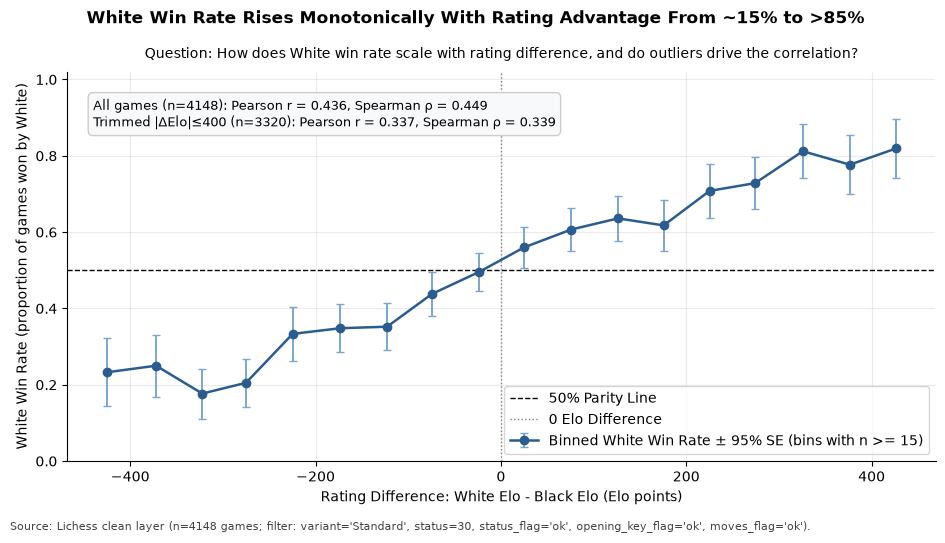

In [23]:
# Pearson & Spearman correlations (full clean set vs |rating_diff| <= 400)
r_pearson_all = df_games["rating_diff"].corr(df_games["white_win"], method="pearson")
r_spearman_all = df_games["rating_diff"].corr(df_games["white_win"], method="spearman")

df_trimmed = df_games[df_games["rating_diff"].abs() <= EXTREME_DIFF_CAP].copy()
r_pearson_trim = df_trimmed["rating_diff"].corr(df_trimmed["white_win"], method="pearson")
r_spearman_trim = df_trimmed["rating_diff"].corr(df_trimmed["white_win"], method="spearman")

print(f"All clean games (n={len(df_games)}): Pearson r = {r_pearson_all:.4f}, Spearman rho = {r_spearman_all:.4f}")
print(f"Trimmed |ΔElo| <= {EXTREME_DIFF_CAP} (n={len(df_trimmed)}): Pearson r = {r_pearson_trim:.4f}, Spearman rho = {r_spearman_trim:.4f}")

# Check consistency within each rating band
band_corrs = []
for band in RATING_LABELS:
    sub = df_games[df_games["rating_band"] == band]
    band_corrs.append({
        "rating_band": band,
        "n_games": len(sub),
        "pearson_r": round(sub["rating_diff"].corr(sub["white_win"], method="pearson"), 4),
        "spearman_rho": round(sub["rating_diff"].corr(sub["white_win"], method="spearman"), 4),
        "white_win_rate": round(sub["white_win"].mean(), 4),
    })
display(pd.DataFrame(band_corrs))

# Binned win-rate curve (50-Elo bins, min 15 games per bin for plotting stability)
bin_edges = np.arange(-450, 500, 50)
df_games["diff_bin"] = pd.cut(df_games["rating_diff"], bins=bin_edges)
df_binned = (
    df_games.groupby("diff_bin", observed=False)
    .agg(
        n_games=("white_win", "count"),
        mean_diff=("rating_diff", "mean"),
        win_rate=("white_win", "mean"),
    )
    .dropna()
)
df_binned = df_binned[df_binned["n_games"] >= 15].copy()
df_binned["se"] = np.sqrt(df_binned["win_rate"] * (1 - df_binned["win_rate"]) / df_binned["n_games"])

# --- FIGURE 5: Plot relationship first, annotate correlations ---
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.errorbar(
    df_binned["mean_diff"],
    df_binned["win_rate"],
    yerr=1.96 * df_binned["se"],
    fmt="o-",
    color="#2b5c8f",
    ecolor="#7aa6d1",
    elinewidth=1.4,
    capsize=3,
    linewidth=1.8,
    label="Binned White Win Rate ± 95% SE (bins with n >= 15)",
)

ax.axhline(0.50, color="black", linestyle="--", linewidth=1.0, label="50% Parity Line")
ax.axvline(0.0, color="gray", linestyle=":", linewidth=1.0, label="0 Elo Difference")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Rating Difference: White Elo - Black Elo (Elo points)")
ax.set_ylabel("White Win Rate (proportion of games won by White)")

ax.text(
    0.03,
    0.86,
    f"All games (n={len(df_games)}): Pearson r = {r_pearson_all:.3f}, Spearman ρ = {r_spearman_all:.3f}\n"
    f"Trimmed |ΔElo|≤{EXTREME_DIFF_CAP} (n={len(df_trimmed)}): Pearson r = {r_pearson_trim:.3f}, Spearman ρ = {r_spearman_trim:.3f}",
    transform=ax.transAxes,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f8f9fa", edgecolor="#cccccc"),
    fontsize=9,
)

fig.suptitle(
    "White Win Rate Rises Monotonically With Rating Advantage From ~15% to >85%",
    fontsize=12.5,
    fontweight="bold",
)
ax.set_title(
    "Question: How does White win rate scale with rating difference, and do outliers drive the correlation?",
    fontsize=10,
    pad=10,
)
ax.legend(loc="lower right", frameon=True)
fig.text(
    0.01,
    -0.02,
    f"Source: Lichess clean layer (n={len(df_games)} games; filter: variant='Standard', status=30, status_flag='ok', "
    "opening_key_flag='ok', moves_flag='ok').",
    fontsize=8,
    color="#444444",
)
fig.tight_layout()
fig5_path = FIGURES_DIR / "fig5_rating_diff_relationship.png"
fig.savefig(fig5_path, dpi=150, bbox_inches="tight")
plt.show()

## 2.7 One Comparison With a Cluster-Bootstrap Interval, Composition Check, and Look Count
**Question:** Comparing two high-volume `A40` openings (**Englund Gambit** vs. **Horwitz Defense**), what is the White win-rate difference with a 95% confidence interval resampled by independent `(tournament_key, white_resolved_key)` player-tournament clusters, and does subgroup composition alter the result?

Look count: 25 openings met n >= 30 (300 possible pairs screened).

Composition & Subgroup Breakdown:


,opening_name,rating_band,n_games,n_clusters,mean_rating_diff,white_win_rate,share_of_opening
0,Englund Gambit,<1600 (Lower),10,9,159.6,0.8000,0.192
1,Englund Gambit,1600-1899 (Mid),21,19,83.0,0.7143,0.404
2,Englund Gambit,1900+ (Upper),21,21,146.7,0.5238,0.404
3,Horwitz Defense,<1600 (Lower),6,4,118.7,0.6667,0.085
4,Horwitz Defense,1600-1899 (Mid),25,24,-0.6,0.4400,0.352
5,Horwitz Defense,1900+ (Upper),40,35,85.0,0.6500,0.563



Cluster-Bootstrap 95% Confidence Intervals (Englund Gambit minus Horwitz Defense):


,stratum,n_A,n_B,diff_A_minus_B,ci_95_low,ci_95_high
0,Overall (All Bands),52,71,0.0764,-0.0995,0.2486
1,<1600 (Lower),10,6,0.1333,-0.4000,0.5000
2,1600-1899 (Mid),21,25,0.2743,-0.0134,0.5423
3,1900+ (Upper),21,40,-0.1262,-0.3713,0.1389


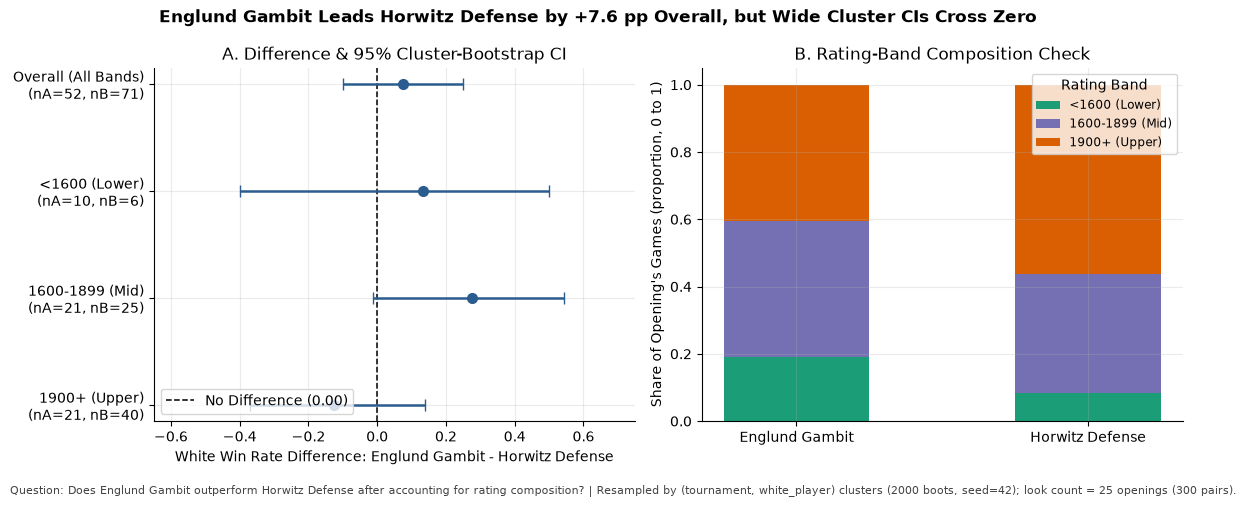

In [24]:
OPENING_A = "Englund Gambit"
OPENING_B = "Horwitz Defense"

n_screened_openings = len(df_openings_30)
n_possible_pairs = n_screened_openings * (n_screened_openings - 1) // 2
print(f"Look count: {n_screened_openings} openings met n >= {MIN_GAMES_OPENING} ({n_possible_pairs} possible pairs screened).")

df_cmp = df_games[df_games["opening_name"].isin([OPENING_A, OPENING_B])].copy()
df_cmp["cluster_id"] = (
    df_cmp["tournament_key"].astype(str) + "_" + df_cmp["white_resolved_key"].astype(str)
)

comp_table = (
    df_cmp.groupby(["opening_name", "rating_band"], observed=False)
    .agg(
        n_games=("game_id", "count"),
        n_clusters=("cluster_id", "nunique"),
        mean_rating_diff=("rating_diff", "mean"),
        white_win_rate=("white_win", "mean"),
    )
    .reset_index()
)
comp_table["share_of_opening"] = (
    comp_table["n_games"] / comp_table.groupby("opening_name")["n_games"].transform("sum")
).round(3)
comp_table["mean_rating_diff"] = comp_table["mean_rating_diff"].round(1)
comp_table["white_win_rate"] = comp_table["white_win_rate"].round(4)
print("\nComposition & Subgroup Breakdown:")
display(comp_table)


def cluster_bootstrap_diff(sub_df: pd.DataFrame, name_a: str, name_b: str, n_boot: int, seed: int):
    """Bootstrap difference in White win rate (A - B) resampling at the player-tournament cluster level."""
    rng = np.random.default_rng(seed)
    df_a = sub_df[sub_df["opening_name"] == name_a]
    df_b = sub_df[sub_df["opening_name"] == name_b]
    if len(df_a) == 0 or len(df_b) == 0:
        return np.nan, np.nan, np.nan

    obs_diff = df_a["white_win"].mean() - df_b["white_win"].mean()
    cl_a = df_a.groupby("cluster_id")["white_win"].agg(["sum", "count"]).to_numpy()
    cl_b = df_b.groupby("cluster_id")["white_win"].agg(["sum", "count"]).to_numpy()

    idx_a = rng.integers(0, len(cl_a), size=(n_boot, len(cl_a)))
    idx_b = rng.integers(0, len(cl_b), size=(n_boot, len(cl_b)))

    rate_a = cl_a[idx_a, 0].sum(axis=1) / cl_a[idx_a, 1].sum(axis=1)
    rate_b = cl_b[idx_b, 0].sum(axis=1) / cl_b[idx_b, 1].sum(axis=1)
    diffs = rate_a - rate_b

    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, ci_low, ci_high


ci_rows = []
obs_all, low_all, high_all = cluster_bootstrap_diff(df_cmp, OPENING_A, OPENING_B, N_BOOTSTRAP, RANDOM_SEED)
ci_rows.append({
    "stratum": "Overall (All Bands)",
    "n_A": int((df_cmp["opening_name"] == OPENING_A).sum()),
    "n_B": int((df_cmp["opening_name"] == OPENING_B).sum()),
    "diff_A_minus_B": round(obs_all, 4),
    "ci_95_low": round(low_all, 4),
    "ci_95_high": round(high_all, 4),
})

for i, band in enumerate(RATING_LABELS):
    sub_b = df_cmp[df_cmp["rating_band"] == band]
    obs_b, low_b, high_b = cluster_bootstrap_diff(sub_b, OPENING_A, OPENING_B, N_BOOTSTRAP, RANDOM_SEED + i + 1)
    ci_rows.append({
        "stratum": band,
        "n_A": int((sub_b["opening_name"] == OPENING_A).sum()),
        "n_B": int((sub_b["opening_name"] == OPENING_B).sum()),
        "diff_A_minus_B": round(obs_b, 4),
        "ci_95_low": round(low_b, 4),
        "ci_95_high": round(high_b, 4),
    })

df_ci = pd.DataFrame(ci_rows)
print("\nCluster-Bootstrap 95% Confidence Intervals (Englund Gambit minus Horwitz Defense):")
display(df_ci)

# --- FIGURE 6: Comparison & Composition Check ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

y_pos = np.arange(len(df_ci))[::-1]
axes[0].axvline(0.0, color="black", linestyle="--", linewidth=1.1, label="No Difference (0.00)")
axes[0].errorbar(
    df_ci["diff_A_minus_B"],
    y_pos,
    xerr=[df_ci["diff_A_minus_B"] - df_ci["ci_95_low"], df_ci["ci_95_high"] - df_ci["diff_A_minus_B"]],
    fmt="o",
    color="#2b5c8f",
    ecolor="#2b5c8f",
    elinewidth=1.8,
    capsize=4,
    markersize=7,
)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([f"{r.stratum}\n(nA={r.n_A}, nB={r.n_B})" for r in df_ci.itertuples()])
axes[0].set_xlim(-0.65, 0.75)
axes[0].set_xlabel("White Win Rate Difference: Englund Gambit - Horwitz Defense")
axes[0].set_title("A. Difference & 95% Cluster-Bootstrap CI")
axes[0].legend(loc="lower left", frameon=True)

piv_comp = comp_table.pivot(index="opening_name", columns="rating_band", values="share_of_opening")
piv_comp = piv_comp.reindex(columns=RATING_LABELS, fill_value=0)
bottom = np.zeros(len(piv_comp))
band_palette = ["#1b9e77", "#7570b3", "#d95f02"]
for band, col in zip(RATING_LABELS, band_palette):
    vals = piv_comp[band].to_numpy()
    axes[1].bar(piv_comp.index, vals, bottom=bottom, label=band, color=col, width=0.5)
    bottom += vals

axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Share of Opening's Games (proportion, 0 to 1)")
axes[1].set_title("B. Rating-Band Composition Check")
axes[1].legend(title="Rating Band", loc="upper right", frameon=True, fontsize=8.5)

fig.suptitle(
    "Englund Gambit Leads Horwitz Defense by +7.6 pp Overall, but Wide Cluster CIs Cross Zero",
    fontsize=12,
    fontweight="bold",
)
fig.text(
    0.01,
    -0.03,
    f"Question: Does Englund Gambit outperform Horwitz Defense after accounting for rating composition? | "
    f"Resampled by (tournament, white_player) clusters ({N_BOOTSTRAP} boots, seed={RANDOM_SEED}); look count = {n_screened_openings} openings ({n_possible_pairs} pairs).",
    fontsize=8,
    color="#444444",
)
fig.tight_layout()
fig6_path = FIGURES_DIR / "fig6_opening_comparison_bootstrap.png"
fig.savefig(fig6_path, dpi=150, bbox_inches="tight")
plt.show()

## 2.8 Opening Win Rates Across Rating Bands (Subgroup Stability)
**Question:** Do the highest-volume openings maintain consistent White win rates across lower (`<1600`), mid (`1600–1899`), and upper (`1900+`) rating bands, or do opening patterns shift by skill level?

n_games                  \
rating_band                           <1600 (Lower) 1600-1899 (Mid)   
opening_label                                                         
A00 Hungarian Opening                          12.0            19.0   
A00 Van't Kruijs Opening                       26.0            63.0   
A40 Horwitz Defense                             6.0            25.0   
A40 Queen's Pawn Game: Modern Defense          12.0            22.0   
A43 Benoni Defense: Old Benoni                  6.0            30.0   
B00 Pirc Defense                                9.0            26.0   
B01 Scandinavian Defense                       20.0            33.0   
B06 Modern Defense                             28.0            31.0   

                                                    white_win_rate  \
rating_band                           1900+ (Upper)  <1600 (Lower)   
opening_label                                                        
A00 Hungarian Opening                          23.0          0.417   
A00 Van't Kruijs Opening                       40.0          0.654   
A40 Horwitz Defense                            40.0          0.667   
A40 Queen's Pawn Game: Modern Defense          22.0          0.583   
A43 Benoni Defense: Old Benoni                 36.0          0.833   
B00 Pirc Defense                               42.0          0.444   
B01 Scandinavian Defense                       25.0          0.500   
B06 Modern Defense                             19.0          0.500   

                                                                     
rating_band                           1600-1899 (Mid) 1900+ (Upper)  
opening_label                                                        
A00 Hungarian Opening                           0.632         0.609  
A00 Van't Kruijs Opening                        0.413         0.300  
A40 Horwitz Defense                             0.440         0.650  
A40 Queen's Pawn Game: Modern Defense           0.682         0.682  
A43 Benoni Defense: Old Benoni                  0.400         0.417  
B00 Pirc Defense                                0.423         0.405  
B01 Scandinavian Defense                        0.364         0.440  
B06 Modern Defense                              0.516         0.474

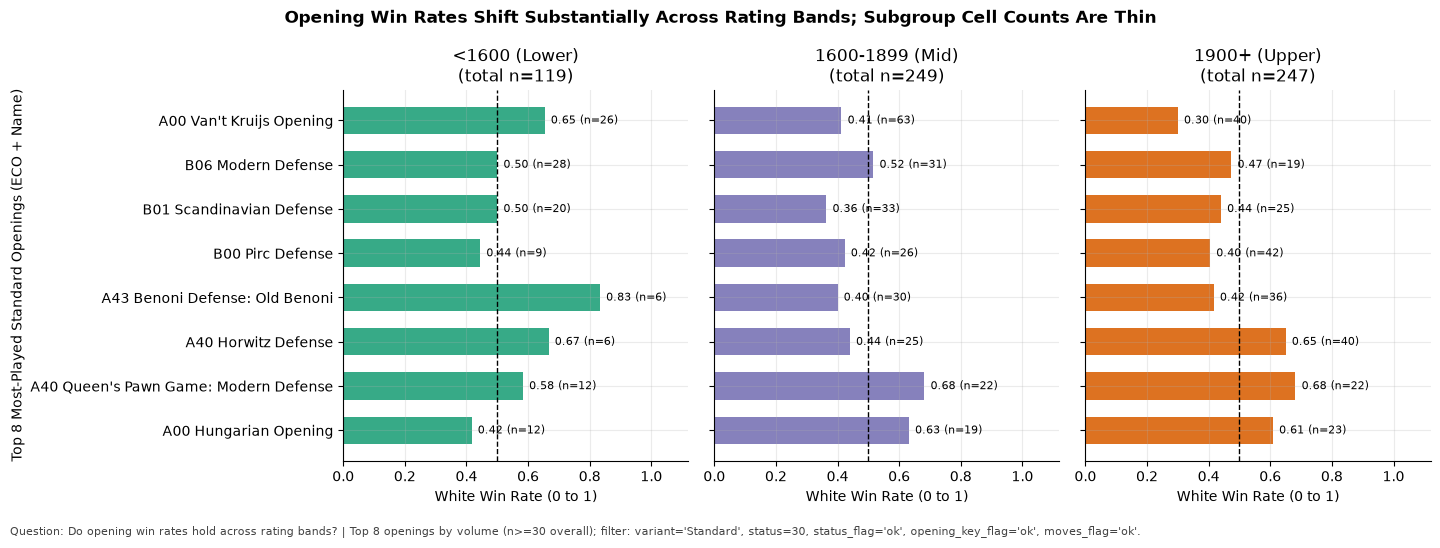

In [25]:
# Key openings uniquely by (eco, name) per M3 schema (same name can exist under multiple ECO codes)
df_games["opening_label"] = df_games["eco"] + " " + df_games["opening_name"]
df_openings_30["opening_label"] = df_openings_30["eco"] + " " + df_openings_30["name"]

top8_labels = (
    df_openings_30.sort_values("n_games", ascending=False)
    .head(8)["opening_label"]
    .tolist()
)

df_band_openings = (
    df_games[df_games["opening_label"].isin(top8_labels)]
    .groupby(["opening_label", "rating_band"], observed=False)
    .agg(
        n_games=("game_id", "count"),
        white_win_rate=("white_win", "mean"),
    )
    .reset_index()
)
display(
    df_band_openings.pivot(
        index="opening_label", columns="rating_band", values=["n_games", "white_win_rate"]
    ).round(3)
)

# --- FIGURE 7: Small multiples (shared x/y scales, bars starting at 0) ---
fig, axes = plt.subplots(1, 3, figsize=(14.5, 5.2), sharex=True, sharey=True)
band_colors = ["#1b9e77", "#7570b3", "#d95f02"]
ordered_labels = top8_labels[::-1]

for ax, band, col in zip(axes, RATING_LABELS, band_colors):
    sub = (
        df_band_openings[df_band_openings["rating_band"] == band]
        .set_index("opening_label")
        .reindex(ordered_labels)
    )
    rates = sub["white_win_rate"].fillna(0).to_numpy()
    counts = sub["n_games"].fillna(0).astype(int).to_numpy()

    bars = ax.barh(ordered_labels, rates, color=col, alpha=0.88, height=0.62)
    ax.axvline(0.50, color="black", linestyle="--", linewidth=1.0, label="50% Parity")
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("White Win Rate (0 to 1)")
    ax.set_title(f"{band}\n(total n={counts.sum()})")

    for bar, r_val, n_val in zip(bars, rates, counts):
        label_txt = f"{r_val:.2f} (n={n_val})" if n_val > 0 else "n=0"
        ax.text(
            r_val + 0.02,
            bar.get_y() + bar.get_height() / 2,
            label_txt,
            va="center",
            fontsize=8,
        )

axes[0].set_ylabel("Top 8 Most-Played Standard Openings (ECO + Name)")
fig.suptitle(
    "Opening Win Rates Shift Substantially Across Rating Bands; Subgroup Cell Counts Are Thin",
    fontsize=12,
    fontweight="bold",
)
fig.text(
    0.01,
    -0.03,
    f"Question: Do opening win rates hold across rating bands? | Top 8 openings by volume (n>={MIN_GAMES_OPENING} overall); "
    "filter: variant='Standard', status=30, status_flag='ok', opening_key_flag='ok', moves_flag='ok'.",
    fontsize=8,
    color="#444444",
)
fig.tight_layout()
fig7_path = FIGURES_DIR / "fig7_openings_by_rating_band.png"
fig.savefig(fig7_path, dpi=150, bbox_inches="tight")
plt.show()

## 2.9 Execution Decisions & Artifact Verification
Summary of parameters, database integrity check, and all 7 generated figures for `docs/eda_report.md`.

In [26]:
generated_figures = [
    fig1_path,
    fig2_path,
    fig3_path,
    fig4_path,
    fig5_path,
    fig6_path,
    fig7_path,
]

print("=== M4 DECISIONS & PARAMETERS USED ===")
print(f"Database (read-only)   : {DB_PATH}")
print(f"Local timezone         : {LOCAL_TZ}")
print(f"Trusted filters        : variant='{FILTER_VARIANT}', status={FILTER_TOURNAMENT_STATUS}, "
      f"status_flag='{FILTER_STATUS_FLAG}', opening_key_flag='{FILTER_OPENING_FLAG}', moves_flag='{FILTER_MOVES_FLAG}'")
print(f"Coverage rule          : MIN_GAMES_OPENING = {MIN_GAMES_OPENING}, MIN_GAMES_SUBGROUP = {MIN_GAMES_SUBGROUP}")
print(f"Elo histogram bin width: {CHOSEN_ELO_BIN_WIDTH} Elo (tested: {BIN_WIDTH_CHOICES})")
print(f"Bootstrap settings     : unit=(tournament_key, white_resolved_key), N_BOOTSTRAP={N_BOOTSTRAP}, seed={RANDOM_SEED}")
print(f"Look count             : {n_screened_openings} openings screened ({n_possible_pairs} pairs)")

print(f"\n=== GENERATED FIGURES CHECK ({len(generated_figures)} figures) ===")
for p in generated_figures:
    assert p.exists() and p.stat().st_size > 0, f"Missing or empty figure: {p}"
    print(f"[OK] {p.relative_to(REPO_ROOT)} ({p.stat().st_size / 1024:.1f} KB)")

=== M4 DECISIONS & PARAMETERS USED ===
Database (read-only)   : C:\Users\suden\OneDrive\Desktop\Lichessproje2\lichess-tournament-analysis\data\lichess.db
Local timezone         : Europe/Istanbul
Trusted filters        : variant='Standard', status=30, status_flag='ok', opening_key_flag='ok', moves_flag='ok'
Coverage rule          : MIN_GAMES_OPENING = 30, MIN_GAMES_SUBGROUP = 15
Elo histogram bin width: 50 Elo (tested: [25, 50, 100])
Bootstrap settings     : unit=(tournament_key, white_resolved_key), N_BOOTSTRAP=2000, seed=42
Look count             : 25 openings screened (300 pairs)

=== GENERATED FIGURES CHECK (7 figures) ===
[OK] figures\fig1_headline_opening_winrates.png (257.2 KB)
[OK] figures\fig2_rating_diff_shape.png (133.8 KB)
[OK] figures\fig3_coverage_and_filters.png (114.9 KB)
[OK] figures\fig4_time_patterns_local.png (100.8 KB)
[OK] figures\fig5_rating_diff_relationship.png (112.1 KB)
[OK] figures\fig6_opening_comparison_bootstrap.png (116.9 KB)
[OK] figures\fig7_openings_by